In [1]:
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
import glob
import datetime as dt
import pickle as pkl
from scipy.interpolate import interp1d, RegularGridInterpolator
from matplotlib.ticker import ScalarFormatter
import os
import jdcal
import math
from scipy.stats import linregress
import sim_name_remap as map
import plotter_config as pc

In [2]:

def get_ACCLIP_merge_data(OBSROOT, FLT_DATES, var_str):
    
    OBSvar = []

    if var_str != '':
        for FLT_DATE in FLT_DATES:
        
            AIRFILE = glob.glob(OBSROOT + '*' + FLT_DATE + '*.ict')[0]     
            AIRheaders = np.loadtxt(AIRFILE, delimiter=',', usecols = (0), dtype='str')
            AIRdata = np.loadtxt(AIRFILE, delimiter=',', skiprows=int(AIRheaders[0]))  # Read the file
            OBSvar.extend(AIRdata[:,int(list(AIRheaders).index(var_str))-11])
        
    return np.asarray(OBSvar)
    

In [3]:

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'
var_lab = 'CO'
flt_date = '20220819'


##############################################
WE BEGIN WITH THE GV FIGURE
##############################################

In [4]:

# Read the files generated by calc_aircraft_interp.py


with open(SAVEDIR + '2022_E5-strong_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_E5_strong_lon, GV_E5_strong_lat, GV_E5_strong_prs, GV_E5_strong_alt, GV_E5_strong_jd, var_lab, GV_E5_strong_var_interp = pkl.load(f)
with open(SAVEDIR + '2022_E5-weak_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_E5_weak_lon, GV_E5_weak_lat, GV_E5_weak_prs, GV_E5_weak_alt, GV_E5_weak_jd, var_lab, GV_E5_weak_var_interp = pkl.load(f)

with open(SAVEDIR + '2022_M2-strong_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_M2_strong_lon, GV_M2_strong_lat, GV_M2_strong_prs, GV_M2_strong_alt, GV_M2_strong_jd, var_lab, GV_M2_strong_var_interp = pkl.load(f)
with open(SAVEDIR + '2022_M2-weak_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_M2_weak_lon, GV_M2_weak_lat, GV_M2_weak_prs, GV_M2_weak_alt, GV_M2_weak_jd, var_lab, GV_M2_weak_var_interp = pkl.load(f)

with open(SAVEDIR + '2022_FreeRun_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_FreeRun_lon, GV_FreeRun_lat, GV_FreeRun_prs, GV_FreeRun_alt, GV_FreeRun_jd, var_lab, GV_FreeRun_var_interp = pkl.load(f)
    
GV_hr = []
for pt in GV_E5_strong_jd:
    GV_hr.append((pt - math.floor(pt) - 0.5)*24.)


with open(SAVEDIR + '2022_E5-strong_WB57_' + var_lab + '_1D_interp.pkl','rb') as f:
    WB_E5_strong_lon, WB_E5_strong_lat, WB_E5_strong_prs, WB_E5_strong_alt, WB_E5_strong_jd, var_lab, WB_E5_strong_var_interp = pkl.load(f)
with open(SAVEDIR + '2022_E5-weak_WB57_' + var_lab + '_1D_interp.pkl','rb') as f:
    WB_E5_weak_lon, WB_E5_weak_lat, WB_E5_weak_prs, WB_E5_weak_alt, WB_E5_weak_jd, var_lab, WB_E5_weak_var_interp = pkl.load(f)

with open(SAVEDIR + '2022_M2-strong_WB57_' + var_lab + '_1D_interp.pkl','rb') as f:
    WB_M2_strong_lon, WB_M2_strong_lat, WB_M2_strong_prs, WB_M2_strong_alt, WB_M2_strong_jd, var_lab, WB_M2_strong_var_interp = pkl.load(f)
with open(SAVEDIR + '2022_M2-weak_WB57_' + var_lab + '_1D_interp.pkl','rb') as f:
    WB_M2_weak_lon, WB_M2_weak_lat, WB_M2_weak_prs, WB_M2_weak_alt, WB_M2_weak_jd, var_lab, WB_M2_weak_var_interp = pkl.load(f)

with open(SAVEDIR + '2022_FreeRun_WB57_' + var_lab + '_1D_interp.pkl','rb') as f:
    WB_FreeRun_lon, WB_FreeRun_lat, WB_FreeRun_prs, WB_FreeRun_alt, WB_FreeRun_jd, var_lab, WB_FreeRun_var_interp = pkl.load(f)
    
WB_hr = []
for pt in WB_E5_strong_jd:
    WB_hr.append((pt - math.floor(pt) - 0.5)*24.)
    

In [5]:

# Read the observations

GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'

GV_alt = get_ACCLIP_merge_data(GV_OBSROOT, [flt_date], 'GGALT')*1.e-3
GV_CO  = get_ACCLIP_merge_data(GV_OBSROOT, [flt_date], 'CO_AERODYNE')
GV_SO4 = get_ACCLIP_merge_data(GV_OBSROOT, [flt_date], 'sulphate_AMS')   # Raw units of ug/m3
GV_SO2 = get_ACCLIP_merge_data(GV_OBSROOT, [flt_date], 'SO2_GTCIMS')

WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'

WB_alt  = get_ACCLIP_merge_data(WB_OBSROOT, ['20220819'], 'G_ALT_MMS')*1.e-3
WB_CO   = get_ACCLIP_merge_data(WB_OBSROOT, ['20220819'], 'CO_COLD2_ppbv')  #  'ACOS_CO_PPB')


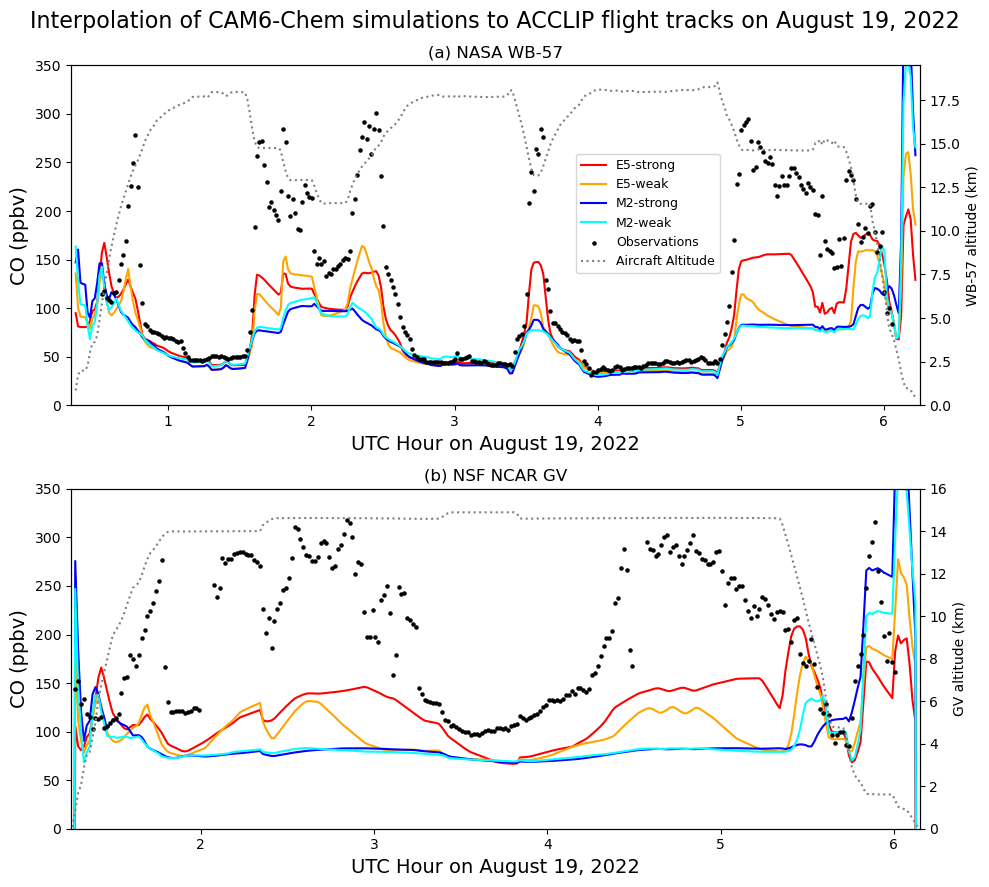

In [6]:

#if sim == 'Aug19_ERA5_0.25nudge': col = 'blue'
#if sim == 'Aug19_ERA5_0.25nudge_noZMKE': col = 'orange'

fig = plt.figure(figsize=(10,9))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)

ax1.plot(WB_hr, WB_E5_strong_var_interp, color='red', label='E5-strong')
ax1.plot(WB_hr, WB_E5_weak_var_interp, color='orange', label='E5-weak')
ax1.plot(WB_hr, WB_M2_strong_var_interp, color='blue', label='M2-strong')
ax1.plot(WB_hr, WB_M2_weak_var_interp, color='cyan', label='M2-weak')
#ax1.plot(WB_hr, WB_FreeRun_var_interp, color='gray', label='FreeRun')

ax2.plot(GV_hr, GV_E5_strong_var_interp, color='red', label='E5-strong')
ax2.plot(GV_hr, GV_E5_weak_var_interp, color='orange', label='E5-weak')
ax2.plot(GV_hr, GV_M2_strong_var_interp, color='blue', label='M2-strong')
ax2.plot(GV_hr, GV_M2_weak_var_interp, color='cyan', label='M2-weak')
#ax2.plot(GV_hr, GV_FreeRun_var_interp, color='gray', label='FreeRun')

ax1.scatter(WB_hr, WB_CO, color='k', s=5, label='Observations', zorder=999)
if var_lab == 'CO': ax2.scatter(GV_hr, GV_CO, color='k', s=5, zorder=999)
#if var_lab == 'SO4': ax2.scatter(GV_hr, GV_SO4, color='k', s=5, label='ACCLIP ERICA Observations', zorder=999)
#if var_lab == 'SO2': ax2.scatter(GV_hr, GV_SO2, color='k', s=5, label='ACCLIP GT-CIMS Observations', zorder=999)

#plt.legend(bbox_to_anchor=(0.72,0.86))

ax1b = ax1.twinx()
ax2b = ax2.twinx()

ax1b.plot(WB_hr, WB_alt, color='gray', linestyle=':', label='Aircraft Altitude')
ax2b.plot(GV_hr, GV_alt, color='gray', linestyle=':')

ax1.set_xlim(0.32,6.25)
ax2.set_xlim(1.25,6.15)

ax1.set_ylim(0,350)
ax2.set_ylim(0,350)
ax1b.set_ylim(0,19.5)
ax2b.set_ylim(0,16)

plt.suptitle('Interpolation of CAM6-Chem simulations to ACCLIP flight tracks on August 19, 2022', fontsize=16)

ax1.set_title('(a) NASA WB-57')
ax2.set_title('(b) NSF NCAR GV')

ax1.set_xlabel('UTC Hour on August 19, 2022', fontsize=14)
ax2.set_xlabel('UTC Hour on August 19, 2022', fontsize=14)

ax1.set_ylabel(var_lab + ' (' + pc.var_info[var_lab]['unit'] + ')', fontsize=14)
ax2.set_ylabel(var_lab + ' (' + pc.var_info[var_lab]['unit'] + ')', fontsize=14)

ax1b.set_ylabel('WB-57 altitude (km)')
ax2b.set_ylabel('GV altitude (km)')

plt.tight_layout()

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax1b.get_legend_handles_labels()
ax1.legend(handles1 + handles2,
           labels1 + labels2, fontsize=9,
           bbox_to_anchor = (0.68,0.37))

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure6.png', dpi=300)
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure6.pdf', dpi=300)


######################################################  DO A GV COMPARISON WITH THE BOOSTED CO SIMULATION ##############################################


# Read the files generated by calc_aircraft_interp.py

with open(SAVEDIR + '2022_MERRA2_ZM_30m_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_M2_ZM_lon, GV_M2_ZM_lat, GV_M2_ZM_prs, GV_M2_ZM_alt, GV_M2_ZM_jd, var_lab, GV_M2_ZM_var_interp = pkl.load(f)
    
with open(SAVEDIR + '2022_ERA5_ZM_30m_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_E5_ZM_lon, GV_E5_ZM_lat, GV_E5_ZM_prs, GV_E5_ZM_alt, GV_E5_ZM_jd, var_lab, GV_E5_ZM_var_interp = pkl.load(f)

with open(SAVEDIR + '2022_ERA5_ZM_30m_COboost_GV_' + var_lab + '_1D_interp.pkl','rb') as f:
    GV_E5_ZM_b_lon, GV_E5_ZM_b_lat, GV_E5_ZM_b_prs, GV_E5_ZM_b_alt, GV_E5_ZM_b_jd, var_lab, GV_E5_ZM_b_var_interp = pkl.load(f)

GV_hr = []
for pt in GV_E5_ZM_jd:
    GV_hr.append((pt - math.floor(pt) - 0.5)*24.)
    


fig = plt.figure(figsize=(10,4))
ax = fig.add_subplot(111)
ax2 = ax.twinx()

if var_lab == 'CO': ax.scatter(GV_hr, GV_CO, color='k', s=2, label='ACCLIP GV Observations')
if var_lab == 'SO4': ax.scatter(GV_hr, GV_SO4, color='k', s=2, label='ACCLIP ERICA Observations')
if var_lab == 'SO2': ax.scatter(GV_hr, GV_SO2, color='k', s=2, label='ACCLIP GT-CIMS Observations')
    
ax2.plot(GV_hr, GV_M2_ZM_var_interp, color='blue', label='MERRA-2_ZM')
ax2.plot(GV_hr, GV_E5_ZM_var_interp, color='red', label='ERA5_ZM')
ax2.plot(GV_hr, GV_E5_ZM_b_var_interp, color='purple', label='ERA5 ZM_boost')

plt.legend(bbox_to_anchor=(0.0,0.0), borderaxespad=0)

ax3 = ax.twinx()
rspine = ax3.spines['right']
rspine.set_position(('axes', 1.15))
ax3.set_frame_on(True)
ax3.patch.set_visible(False)
fig.subplots_adjust(right=0.7)

ax3.plot(GV_hr, GV_alt, color='gray')

ax.set_xlim(1.3,5.8)
ax3.set_ylim(10,15.2)

if var_lab == 'CO':
    ax.set_ylim(20,350)
    ax2.set_ylim(20,350)
if var_lab == 'SO4':
    ax.set_ylim(0.001,10)
    ax2.set_ylim(0.001,10)
    ax.set_yscale('log')
    ax2.set_yscale('log')
if var_lab == 'SO2':
    ax.set_ylim(1,1000)
    ax2.set_ylim(1,1000)
    ax.set_yscale('log')
    ax2.set_yscale('log')    

ax.set_title('Interpolation of CAM6-Chem simulations to ACCLIP GV flight track on August 19, 2022')
ax.set_xlabel('Hour on August 19, 2022 (UTC)')
ax.set_ylabel('Observed ' + var_lab + ' (' + pc.var_info[var_lab]['unit'] + ')')
ax2.set_ylabel('Model Interpolated ' + var_lab + ' (' + pc.var_info[var_lab]['unit'] + ')')
ax3.set_ylabel('GV altitude (km)')



##############################################
NEXT WE MOVE TO THE WB-57 COMPARISON
##############################################

In [7]:

def clean_CO(model_var, obs_var, obs_alt, UT_alt):

    clean_model_var = []
    clean_obs_var = []
    
    for pt in range(len(model_var)):

        if model_var[pt] >= -1 and obs_var[pt] >= -1 and obs_var[pt] < 500 and obs_alt[pt] >= UT_alt[0] and obs_alt[pt] <= UT_alt[1]:

            clean_model_var.append(model_var[pt])
            clean_obs_var.append(obs_var[pt])

    return clean_model_var, clean_obs_var


In [8]:

UT_alt = [12.0,16.0]

clean_E5_strong_model_CO_GV, clean_E5_strong_obs_CO_GV = clean_CO(GV_E5_strong_var_interp, GV_CO, GV_alt, UT_alt)
clean_E5_weak_model_CO_GV, clean_E5_weak_obs_CO_GV = clean_CO(GV_E5_weak_var_interp, GV_CO, GV_alt, UT_alt)
clean_M2_strong_model_CO_GV, clean_M2_strong_obs_CO_GV = clean_CO(GV_M2_strong_var_interp, GV_CO, GV_alt, UT_alt)
clean_M2_weak_model_CO_GV, clean_M2_weak_obs_CO_GV = clean_CO(GV_M2_weak_var_interp, GV_CO, GV_alt, UT_alt)
clean_FreeRun_model_CO_GV, clean_FreeRun_obs_CO_GV = clean_CO(GV_FreeRun_var_interp, GV_CO, GV_alt, UT_alt)

clean_E5_strong_model_CO_WB, clean_E5_strong_obs_CO_WB = clean_CO(WB_E5_strong_var_interp, WB_CO, WB_alt, UT_alt)
clean_E5_weak_model_CO_WB, clean_E5_weak_obs_CO_WB = clean_CO(WB_E5_weak_var_interp, WB_CO, WB_alt, UT_alt)
clean_M2_strong_model_CO_WB, clean_M2_strong_obs_CO_WB = clean_CO(WB_M2_strong_var_interp, WB_CO, WB_alt, UT_alt)
clean_M2_weak_model_CO_WB, clean_M2_weak_obs_CO_WB = clean_CO(WB_M2_weak_var_interp, WB_CO, WB_alt, UT_alt)
clean_FreeRun_model_CO_WB, clean_FreeRun_obs_CO_WB = clean_CO(WB_FreeRun_var_interp, WB_CO, WB_alt, UT_alt)

clean_E5_strong_model_CO = clean_E5_strong_model_CO_GV + clean_E5_strong_model_CO_WB
clean_E5_weak_model_CO = clean_E5_weak_model_CO_GV + clean_E5_weak_model_CO_WB
clean_M2_strong_model_CO = clean_M2_strong_model_CO_GV + clean_M2_strong_model_CO_WB
clean_M2_weak_model_CO = clean_M2_weak_model_CO_GV + clean_M2_weak_model_CO_WB
clean_FreeRun_model_CO = clean_FreeRun_model_CO_GV + clean_FreeRun_model_CO_WB

clean_E5_strong_obs_CO = clean_E5_strong_obs_CO_GV + clean_E5_strong_obs_CO_WB
clean_E5_weak_obs_CO = clean_E5_weak_obs_CO_GV + clean_E5_weak_obs_CO_WB
clean_M2_strong_obs_CO = clean_M2_strong_obs_CO_GV + clean_M2_strong_obs_CO_WB
clean_M2_weak_obs_CO = clean_M2_weak_obs_CO_GV + clean_M2_weak_obs_CO_WB
clean_FreeRun_obs_CO = clean_FreeRun_obs_CO_GV + clean_FreeRun_obs_CO_WB

print(np.min(clean_FreeRun_model_CO), np.max(clean_FreeRun_model_CO))
print(np.min(clean_FreeRun_obs_CO), np.max(clean_FreeRun_obs_CO))


50.09071103480729 112.03945862125295
75.683 317.767


In [9]:

m_E5_strong, b_E5_strong, r_value, p_value, std_err = linregress(clean_E5_strong_obs_CO, clean_E5_strong_model_CO)
m_E5_weak, b_E5_weak, r_value, p_value, std_err = linregress(clean_E5_weak_obs_CO, clean_E5_weak_model_CO)
m_M2_strong, b_M2_strong, r_value, p_value, std_err = linregress(clean_M2_strong_obs_CO, clean_M2_strong_model_CO)
m_M2_weak, b_M2_weak, r_value, p_value, std_err = linregress(clean_M2_weak_obs_CO, clean_M2_weak_model_CO)
m_FreeRun, b_FreeRun, r_value, p_value, std_err = linregress(clean_FreeRun_obs_CO, clean_FreeRun_model_CO)


Text(0.5, 0, 'Airborne in situ CO observations (ppbv)')

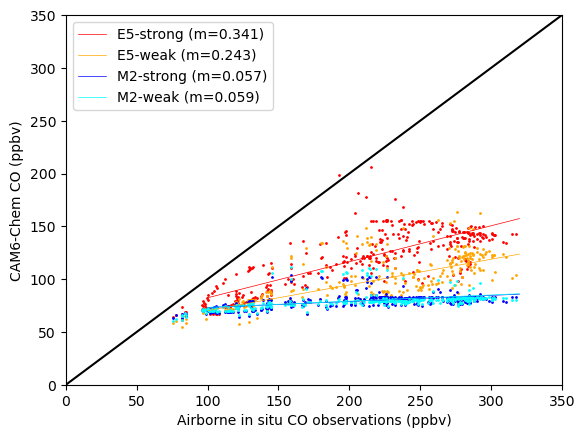

In [10]:

plt.scatter(clean_E5_strong_obs_CO, clean_E5_strong_model_CO, color='red', s=1)
plt.scatter(clean_E5_weak_obs_CO, clean_E5_weak_model_CO, color='orange', s=1)
plt.scatter(clean_M2_strong_obs_CO, clean_M2_strong_model_CO, color='blue', s=1)
plt.scatter(clean_M2_weak_obs_CO, clean_M2_weak_model_CO, color='cyan', s=1)
#plt.scatter(clean_FreeRun_obs_CO, clean_FreeRun_model_CO, color='gray', s=1)

xgrid = np.linspace(100,320,10)

plt.plot(xgrid, m_E5_strong * xgrid + b_E5_strong, color='red', linewidth=0.5, label='E5-strong (m=' + str(round(m_E5_strong,3)) + ')')
plt.plot(xgrid, m_E5_weak * xgrid + b_E5_weak, color='orange', linewidth=0.5, label='E5-weak (m=' + str(round(m_E5_weak,3)) + ')')
plt.plot(xgrid, m_M2_strong * xgrid + b_M2_strong, color='blue', linewidth=0.5, label='M2-strong (m=' + str(round(m_M2_strong,3)) + ')')
plt.plot(xgrid, m_M2_weak * xgrid + b_M2_strong, color='cyan', linewidth=0.5, label='M2-weak (m=' + str(round(m_M2_weak,3)) + ')')
#plt.plot(xgrid, m_FreeRun * xgrid + b_FreeRun, color='gray', linewidth=0.5, label='FreeRun (m=' + str(round(m_FreeRun,3)) + ')')

plt.xlim(0,350)
plt.ylim(0,350)

plt.plot([0,350],[0,350],color='k')

plt.legend()

plt.ylabel('CAM6-Chem CO (ppbv)')
plt.xlabel('Airborne in situ CO observations (ppbv)')
